In [188]:
import torch

### Case 1: dy/dx for y=x**2







- Forward Propagation

In [189]:
x=torch.tensor(3.0,requires_grad=True)

In [190]:
y=x**2

In [191]:
x

tensor(3., requires_grad=True)

In [192]:
y #tensor(9., grad_fn=<PowBackward0>)

#it's output defines that it would remember that which operation has been applied
#so it do backpropagation easily

tensor(9., grad_fn=<PowBackward0>)

- Backward Propagation

In [193]:
y.backward() #all gradients dy/dx are calculated here

In [194]:
x.grad #printing value of gradient

tensor(6.)

In [195]:
y.grad_fn

### Case 2 : dz/dx for z=Sin(y) and y=x**2


- Forward Propagation

In [196]:
x=torch.tensor(3.0,requires_grad=True)

In [197]:
y=x**2

In [198]:
z=torch.sin(y)

In [199]:
x

tensor(3., requires_grad=True)

In [200]:
y

tensor(9., grad_fn=<PowBackward0>)

In [201]:
z

tensor(0.4121, grad_fn=<SinBackward0>)

In [202]:
print(x.grad_fn)

None


In [203]:
print(y.grad_fn) #y is generated from PowBackward

In [204]:
print(y.grad_fn.next_functions) #y's parent generated from leaf so here AccumulateGrad

((<AccumulateGrad object at 0x7a413919c430>, 0),)


In [ ]:
print(x.grad_fn) # x is an leaf and when gard_fn called on it,it returns None

None


if we run the .grad before the backpropagation thn it would store None value because after backproapgation teh result is stored in the .grad

In [206]:
print(x.grad)

None


- Backward Propagation

When you call .backward(), PyTorch traverses that graph from the loss down to your parameters, calculates the gradients, and immediately deletes the gradients of all intermediate nodes once they have finished passing the signal along. It only saves gradients for leaf tensors (like $w$, $x$, and $b$) because those are the parameters your optimizer actually needs to update weights.
- Hence I have to use
 y.retain_grad() and z.retain_grad() to get the dy/dz and dz/dz  to store the intermediate gradients
- if you run without tyhat retain_grad() then it would throw error as it gives gradient for only roots

In [207]:
y.retain_grad()

In [208]:
z.retain_grad()

In [209]:
z.backward() #.backward called on final tensor scalar that represent the loss

In [210]:
x.grad #represent dz/dx

tensor(-5.4668)

In [211]:
z.grad #represent dz/dz

tensor(1.)

In [212]:
y.grad #represent dz/dy

tensor(-0.9111)

in in DAG(directed acyclic graph) leaves are input tensors and roots are output tensors

when .backward() is called, autograd then:
- computes gradients from each .grad_fn
- accumumalte them in the respective tensor's .grad attribute

## _version

a small counter that goes up every time the tensor is edited in place (+=, .add_(), x[0] = 5, and so on).




In [213]:
a=torch.tensor(1.0)
print(a._version)

0


In [214]:
a.add_(1) #_version would increment for only inplace changes not for temporary changes

tensor(2.)

In [215]:
a

tensor(2.)

In [216]:
print(a._version)

1


## detach(): cutting a tensor out of the graph
- detach() gives you a tensor with the same numbers but no history. It shares the same memory, so editing one changes the other. It is like photocopying a page and tearing off the notebook: you keep the values and drop the tracking.

- Use it when you want to use a value without letting gradients flow through it, for example logging a loss or a target that should be treated as a constant.

In [217]:
d=torch.tensor([1.,2.,3.] ,requires_grad=True)

In [218]:
d

tensor([1., 2., 3.], requires_grad=True)

In [219]:
d.detach()

tensor([1., 2., 3.])

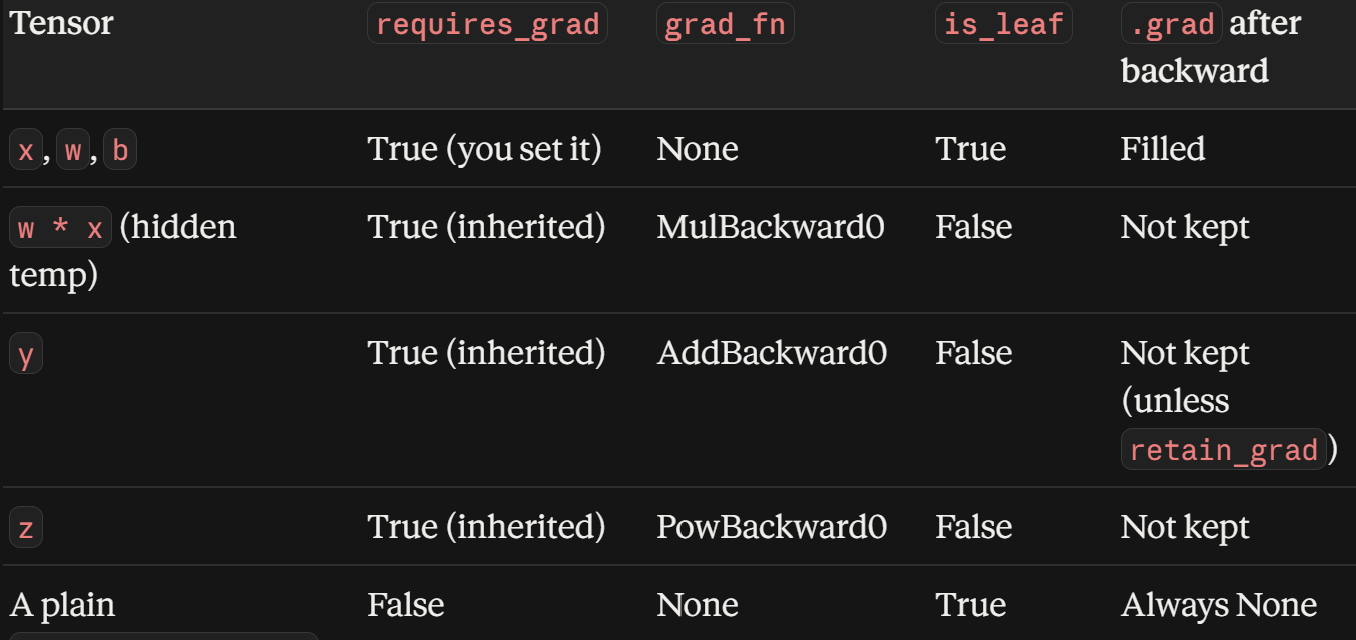

- Is requires_grad True? If not, autograd ignores it.
Is grad_fn None? If yes, it's either a leaf, a detached tensor, or was made under no_grad.
- Is it a leaf? If yes, expect its gradient in .grad. If no, the gradient passes through and is discarded.
- Was it edited in place? Check _version if you ever see an "modified by an inplace operation" error.

## Practical implementation


In [220]:
x=torch.tensor(3.0)
y=torch.tensor(0.0)

In [221]:
w=torch.tensor(1.0,requires_grad=True)
b=torch.tensor(0.0,requires_grad=True)

In [222]:
#Binary Cross-Entropy Loss fro Scalar
def binary_cross_entropy_loss(prediction,target):
  epsilon=1e-8
  prediction=torch.clamp(prediction,epsilon,1-epsilon)
  return -(target+torch.log(prediction)+(1-target)*torch.log(1-prediction))

- Forward Pass

In [223]:
z=w*x+b
z

tensor(3., grad_fn=<AddBackward0>)

In [224]:
y_pred=torch.sigmoid(z)
y_pred

tensor(0.9526, grad_fn=<SigmoidBackward0>)

In [225]:
#compute binary cross-entropy loss
loss=binary_cross_entropy_loss(y_pred,y)
loss

tensor(3.0972, grad_fn=<NegBackward0>)

Backward Pass(manual)

In [226]:
#derivatives:
# 1. dL/d(y_pred): Loss wrt prediction(y_pred)
dloss_dy_pred=(y_pred-y)/(y_pred*(1-y_pred))

#2. dy_pred/dz: Prediction (y_pred) wrt z(sigmoid derivative)
dy_pred_dz=y_pred*(1-y_pred)

#3. dz/dw and dz/db
dz_dw=x
dz_db=1

dL_dw=dloss_dy_pred*dy_pred_dz*dz_dw
dL_db=dloss_dy_pred*dy_pred_dz*dz_db

In [227]:
print(f"Manual Gradient of Loss wrt weight(dw): {dL_dw}")
print(f"Manual Gradient of Loss wrt bias(db): {dL_db}")


Manual Gradient of Loss wrt weight(dw): 2.857722282409668
Manual Gradient of Loss wrt bias(db): 0.9525741338729858


Backward Pass (using autoGrad)

In [228]:
x=torch.tensor(6.7)
y=torch.tensor(0.0)

In [229]:
w=torch.tensor(1.0,requires_grad=True)
b=torch.tensor(0.0,requires_grad=True)

In [230]:
w

tensor(1., requires_grad=True)

In [231]:
b

tensor(0., requires_grad=True)

In [232]:
z=w*x+b

In [233]:
z

tensor(6.7000, grad_fn=<AddBackward0>)

In [234]:
y_pred=torch.sigmoid(z)
y_pred

tensor(0.9988, grad_fn=<SigmoidBackward0>)

In [235]:
loss=binary_cross_entropy_loss(y_pred,y)

In [236]:
loss

tensor(6.7024, grad_fn=<NegBackward0>)

In [237]:
loss.backward()

In [238]:
print(x.grad)

None


In [239]:
w.grad

tensor(6.6835)

In [240]:
b.grad

tensor(0.9975)

- for vector data

In [241]:
x=torch.tensor([1.,2.,3.],requires_grad=True)

In [242]:
y=(x**2).mean()

In [243]:
y

tensor(4.6667, grad_fn=<MeanBackward0>)

In [248]:
y.backward()

In [250]:
print(x.grad) #dy/dx1 , dy/dx2 , dy/dx3

tensor([0.6667, 1.3333, 2.0000])


Clearance of Grad

In [263]:
import torch

# Define a parameter
x = torch.tensor(2.0, requires_grad=True)
y = x**2

# First backward pass (must retain graph to run backward again)
y.backward(retain_graph=True)
print(f"Gradient after 1st backward: {x.grad}")  # expected: dy/dx = 2*x = 4

# Second backward pass (gradients will accumulate/add up)
y.backward()
print(f"Gradient after 2nd backward: {x.grad}")  # expected: 4 + 4 = 8

# To prevent accumulation, we manually zero the gradient
x.grad.zero_()
print(f"Gradient after zero_grad: {x.grad}")      # expected: 0

Gradient after 1st backward: 4.0
Gradient after 2nd backward: 8.0
Gradient after zero_grad: 0.0


### how to stop tracking the gradient

In [264]:
x=torch.tensor(3.,requires_grad=True)
y=torch.tensor(0.,requires_grad=True)

In [266]:
y=x**2

In [268]:
y.backward()

In [269]:
x.grad

tensor(6.)

Three ways to stop tracking grad:
- using require_grad_(False)
- using detach()
- using torch.no_grad()

In [272]:
x.requires_grad_(False)

tensor(3.)

In [273]:
x

tensor(3.)

In [275]:
y=x**2
y

tensor(9.)

In [276]:
y.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn